## Optimization model - v1.1

This notebook runs the optimization model with two applicators, one ROI, and one OAR.

### Setup

In [1]:
# Allows Python to find mosh_src if this notebook is moved
import sys
sys.path.insert(0, "/Users/seanmullane/Desktop/Research_2023/modulated_shielding/")

# Add functionality to parse folders
import os

# Import matplotlib and numpy - helpful Python libraries for scientific computing
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as patches
from matplotlib import ticker
from math import pi
from decimal import Decimal

from scipy import optimize

# Import all MOSH plotting functions
from mosh_src.plotting_functions import *

In [2]:
# Number of bins and dosing grid half-length - both set in TOPAS parameter files
bins_mosh = 85
dose_grid_half_mosh = 2.5 # cm

# Z coordinate of radioactive source - set in TOPAS parameter files
source_transZ_mosh = -0.5 # cm

# Applicator radius - set in TOPAS parameter files
applicator_rad = 0.3

# Computes the lattice length for the simulation space in cm
lattice_mosh = dose_grid_half_mosh*2/bins_mosh

In [3]:
# Assume dose point in center of ROI
dose_point = (0.5, 0.0)

source_rad = [0.03, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9] # cm

# 0 = x, 1 = y, 2 = z
const_axis = 2

# Set the range of our contour plots
# Maximum range set by TOPAS parameter files
rngX = (-1.5, 1.5)
rngY = (-1.5, 1.5)

dose = 100 # % of dose
# Compute the plane of the source
source_plane = cm_to_voxel(np.array(source_transZ_mosh), bins_mosh, lattice_mosh)

In [4]:
# Set rod positions
# In this case, we set a center point (x0, y0) and note that the distance from applicator center to channel center is r = 0.18 cm
# This allows us to calculate coordinates of channels for any applicator center point
app1_center = np.array([-1, -1])
app2_center = np.array([0.5, 0.5])
r = 0.18 # cm
NUM_RODS = 6

# Angles of channel centers from x-axis in radians
thetas = [pi/6, pi/2, 5*pi/6, 7*pi/6, 3*pi/2, 11*pi/6]

# Applicator 1 coordinates
APP1_ROD_POS = []
for t in thetas:
    value = np.array([app1_center[0] + r*np.cos(t), app1_center[1] + r*np.sin(t)])
    APP1_ROD_POS.append(np.round(value, decimals=3))

print(APP1_ROD_POS)

# Applicator 2 coordinates
APP2_ROD_POS = []
for t in thetas:
    value = np.array([app2_center[0] + r*np.cos(t), app2_center[1] + r*np.sin(t)])
    APP2_ROD_POS.append(np.round(value, decimals=3))

print(APP2_ROD_POS)

[array([-0.844, -0.91 ]), array([-1.  , -0.82]), array([-1.156, -0.91 ]), array([-1.156, -1.09 ]), array([-1.  , -1.18]), array([-0.844, -1.09 ])]
[array([0.656, 0.59 ]), array([0.5 , 0.68]), array([0.344, 0.59 ]), array([0.344, 0.41 ]), array([0.5 , 0.32]), array([0.656, 0.41 ])]


In [5]:
## Define relevant functions ##

# Compute the gamma function
def compute_gamma(back_voxel_pos: np.array, rod_position: np.array, scaling: float=1.0) -> float:
    gamma = []
    for r in rod_position:
        gamma.append(1/(np.linalg.norm(back_voxel_pos - r)))
    return np.array(gamma)/scaling

# Select OAR area
# Given X and Y bounds (in cm) for OAR, select appropriate voxels for objective function calculation
def select_region(x: tuple, y: tuple) -> np.ndarray:
    """
    x = (xmin, xmax)
    y = (ymin, ymax)

    Returns:
    - r x c array "oar," where r = xmax - xmin, c = ymax - ymin, and each element is a tuple (x_cm, y_cm) 
    identifying a voxel in the ROI/OAR area
    """
    # convert to voxel space to determine size of oar
    x_vox = cm_to_voxel(np.array(x), bins_mosh, lattice_mosh)
    y_vox = cm_to_voxel(np.array(y), bins_mosh, lattice_mosh)

    # construct empty oar array
    oar = np.empty((np.abs(x_vox[1] - x_vox[0]), np.abs(y_vox[1] - y_vox[0])), dtype=tuple)

    # perform inverse voxel --> cm transformation
    x_inverse = voxel_to_cm(x_vox, bins_mosh, lattice_mosh)
    y_inverse = voxel_to_cm(y_vox, bins_mosh, lattice_mosh)
    
    #x_space = np.arange(x_inverse[0], x_inverse[1], lattice_mosh)
    #y_space = np.arange(y_inverse[0], y_inverse[1], lattice_mosh)

    # linspace has better numerical stability than arange when using non-integer step values
    x_space = np.linspace(x_inverse[0], x_inverse[1], np.shape(oar)[0])
    y_space = np.linspace(y_inverse[0], y_inverse[1], np.shape(oar)[1])

    for i in range(np.shape(x_space)[0]):
        for j in range (np.shape(y_space)[0]):
            oar[i][j] = np.array([x_space[i], y_space[j]])

    return (oar, x_vox, y_vox)

Our next step is to compute $\Gamma^{\text{max}}$ for each voxel in a two-applicator system. In this case, we simply compute the maximum proxy dose for a given voxel with respect to each applicator, and then sum the proxy doses appropriately. For a given voxel $i$:

$$ \Gamma_{i}^{\text{max}} = \Gamma_{i}^{\text{max},1} + \Gamma_{i}^{\text{max},2}$$

where the superscript index specifies the applicator.

In [6]:
# Step 1 - compute GAMMA_MAX for two applicator system
X = voxel_to_cm(np.arange(0, bins_mosh), bins_mosh, lattice_mosh)
Y = voxel_to_cm(np.arange(0, bins_mosh), bins_mosh, lattice_mosh)

Xv, Yv = np.meshgrid(X, Y, indexing='ij')
rod_config = np.array([1, 1, 1, 1, 1, 1])

# Applicator 1
GAMMA_MAX_APP1 = np.empty((bins_mosh, bins_mosh))
for i in range(bins_mosh):
    for j in range(bins_mosh):
        if np.linalg.norm((Xv[i][j] - app1_center[0], Yv[i][j] - app1_center[1])) <= applicator_rad:
            GAMMA_MAX_APP1[i][j] = 0
        else:
            g = compute_gamma(np.array([Xv[i][j], Yv[i][j]]), APP1_ROD_POS)
            GAMMA_MAX_APP1[i][j] = np.dot(g, rod_config)

# Applicator 2
GAMMA_MAX_APP2 = np.empty((bins_mosh, bins_mosh))
for i in range(bins_mosh):
    for j in range(bins_mosh):
        if np.linalg.norm((Xv[i][j] - app2_center[0], Yv[i][j] - app2_center[1])) <= applicator_rad:
            GAMMA_MAX_APP2[i][j] = 0
        else:
            g = compute_gamma(np.array([Xv[i][j], Yv[i][j]]), APP2_ROD_POS)
            GAMMA_MAX_APP2[i][j] = np.dot(g, rod_config)

# Combine appropriately
GAMMA_MAX = GAMMA_MAX_APP1 + GAMMA_MAX_APP2

In [7]:
# Next let's define the ROI and OAR
x_roi = (1.0, 1.5)
y_roi = (0.25, 0.75)

x_oar = (-1.25, -0.75)
y_oar = (-2.0, -1.5)

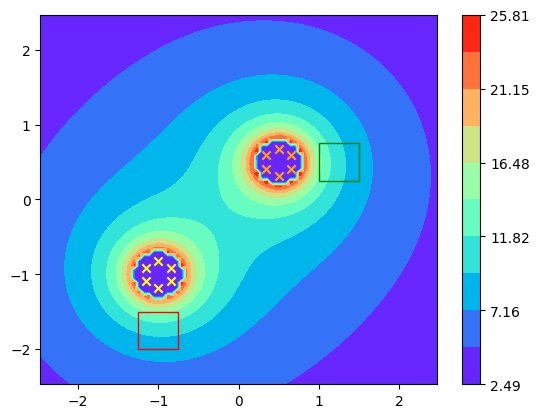

In [8]:
# Plot GAMMA_MAX as a sanity check
fig, ax = plt.subplots()

contour = ax.contourf(Xv, Yv, GAMMA_MAX, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar = fig.colorbar(contour)

for r in APP1_ROD_POS:
    ax.scatter(r[0], r[1], color='yellow', marker='x')

for r in APP2_ROD_POS:
    ax.scatter(r[0], r[1], color='orange', marker='x')

# ROI is green
roi_box = patches.Rectangle((x_roi[0], y_roi[0]), x_roi[1] - x_roi[0], y_roi[1] - y_roi[0], fill=False, edgecolor="green")
ax.add_patch(roi_box)

# OAR is red
oar_box = patches.Rectangle((x_oar[0], y_oar[0]), x_oar[1] - x_oar[0], y_oar[1] - y_oar[0], fill=False, edgecolor="red")
ax.add_patch(oar_box)

In [9]:
# Step 3 - compute gamma_ij for ith voxel, jth rod from each applicator --> store in A matrix per model
# ROI
roi, roi_x_vox, roi_y_vox = select_region(x_roi, y_roi)
roi_voxels = np.shape(roi)[0]*np.shape(roi)[1]

# OAR
oar, oar_x_vox, oar_y_vox = select_region(x_oar, y_oar)
oar_voxels = np.shape(oar)[0]*np.shape(oar)[1]

gamma_storage = []

for i in range(np.shape(roi)[0]):
    for j in range(np.shape(roi)[1]):
        gamma_app1 = compute_gamma(roi[i][j], APP1_ROD_POS)
        gamma_app2 = compute_gamma(roi[i][j], APP2_ROD_POS)
        gamma_storage.append(gamma_app1 + gamma_app2)

for i in range(np.shape(oar)[0]):
    for j in range(np.shape(oar)[1]):
        gamma_app1 = compute_gamma(oar[i][j], APP1_ROD_POS)
        gamma_app2 = compute_gamma(oar[i][j], APP2_ROD_POS)
        gamma_storage.append(gamma_app1 + gamma_app2)

A = np.stack(gamma_storage)
print(np.shape(A))

(145, 6)


In [46]:
# Step 4 - define upper/lower bounds
u_roi = 0.9
l_roi = 0.1

u_oar = 0.4 # try changing this to u_oar = 0.2 to see how the optimization changes
l_oar = 0

In [48]:
# Step 5 - construct upper/lower bound vectors from GAMMA_MAX matrix
upper = []
lower = []
for i in np.arange(roi_x_vox[0], roi_x_vox[1]):
    for j in np.arange(roi_y_vox[0], roi_y_vox[1]):
        upper.append(u_roi*GAMMA_MAX[i][j])
        lower.append(l_roi*GAMMA_MAX[i][j])

for i in np.arange(oar_x_vox[0], oar_x_vox[1]):
    for j in np.arange(oar_y_vox[0], oar_y_vox[1]):
        upper.append(u_oar*GAMMA_MAX[i][j])
        lower.append(0)

upper = np.array(upper)
lower = np.array(lower)

A note about constructing our objective function in this case. We are still constrained to the same objective function structure per the MILP model:

$$\min_{\theta} \vec{c} \cdot \vec{\theta}$$

such that $\vec{l} \leq A \vec{\theta} \leq \vec{u}$ for our constraints matrix and upper/lower bounds. In this case, the vector $\vec{\theta}$ is a sum of rod configuration vectors from each applicator: $\vec{\theta} = \vec{\theta}_1 + \vec{\theta}_2$. We can thus write our full objective function as:

$$ f(\vec{\theta}) = \left( a \sum_{i \in \text{ROI}} \vec{\gamma_i} - b \sum_{k \in \text{OAR}} \vec{\gamma_k} \right) \cdot \vec{\theta} = \left( a \sum_{i \in \text{ROI}} \vec{\gamma_i} - b \sum_{k \in \text{OAR}} \vec{\gamma_k} \right) \cdot (\vec{\theta}_1 + \vec{\theta}_2) = a \sum_{i \in \text{ROI}} \vec{\gamma_i} \cdot (\vec{\theta}_1 + \vec{\theta}_2) - b \sum_{k \in \text{OAR}} \vec{\gamma_k} \cdot (\vec{\theta}_1 + \vec{\theta}_2) $$

Since $\Gamma_{i}^{(1)} = \vec{\gamma}_i \cdot \vec{\theta}_1$ and $\Gamma_{i}^{(2)} = \vec{\gamma}_i \cdot \vec{\theta}_2$ where the superscript represents the applicator number, this reduces to

$$ f(\vec{\theta}) = a \sum_{i \in \text{ROI}} \vec{\gamma_i} \cdot (\vec{\theta}_1 + \vec{\theta}_2) - b \sum_{k \in \text{OAR}} \vec{\gamma_k} \cdot (\vec{\theta}_1 + \vec{\theta}_2) = a \sum_{i \in \text{ROI}} (\Gamma_{i}^{(1)} + \Gamma_{i}^{(2)}) - b \sum_{k \in \text{OAR}} (\Gamma_{k}^{(1)} + \Gamma_{k}^{(2)}) = a \sum_{i \in \text{ROI}} \Gamma_i - b \sum_{k \in \text{OAR}} \Gamma_k $$

Where we've used the fact that the total proxy dose at a given voxel is a sum of the dose contributed by each applicator, so $\Gamma_i = \Gamma_{i}^{(1)} + \Gamma_{i}^{(2)}$. You'll thus note that the objective function for the two applicator case reduces to the same overall form we had for the objective function in the single-applicator case.

However, consider the result of our optimization $\vec{\theta} = \vec{\theta}_1 + \vec{\theta}_2$. Since each element of $\vec{\theta}_1$ and $\vec{\theta}_2$ is either 0 or 1, each element of the vector $\vec{\theta}$ can take on values of 0 (channel closed in both applicators), 1 (channel open in one applicator), or 2 (channel open in both applicators). Let's say we obtain an optimal rod arrangement of $\vec{\theta} = [0, 0, 1, 1, 0, 0]^T$ after running our optimization model. In this case, we know that channels three and four are open, but we can't state which applicators actually have their channels opened. This is because there are multiple combinations of $\vec{\theta}_1$ and $\vec{\theta}_2$ that can sum to the optimal rod arrangement:

$$ \vec{\theta}_1 = [0, 0, 1, 0, 0, 0]^T \ \text{and} \ \vec{\theta}_2 = [0, 0, 0, 1, 0, 0]^T $$
$$ \vec{\theta}_1 = [0, 0, 0, 1, 0, 0]^T \ \text{and} \ \vec{\theta}_2 = [0, 0, 1, 0, 0, 0]^T $$
$$ \vec{\theta}_1 = [0, 0, 1, 1, 0, 0]^T \ \text{and} \ \vec{\theta}_2 = [0, 0, 0, 0, 0, 0]^T $$
$$ \vec{\theta}_1 = [0, 0, 0, 0, 0, 0]^T \ \text{and} \ \vec{\theta}_2 = [0, 0, 1, 1, 0, 0]^T $$

We know the optimal solution is one of these combinations, but the current model cannot tell us which optimization is correct. This ultimately comes from the structure of the MILP problem:

$$\min_{\theta} \vec{c} \cdot \vec{\theta}$$

Since our objective function must be in the form $f(\vec{\theta}) = \vec{c} \cdot \vec{\theta}$, there is no way to "separate out" multiple applicators in our decision vector $\vec{\theta}$ and uniquely identify the optimal solution in the event a channel is open in one applicator and closed in another applicator. Of course, if a given channel is open in both applicators or closed in both applicators, there is no ambiguity.

Fortunately, for a small number of applicators we can simply compute the total dose in the ROI and OAR across all combinations of possible optimal solutions, and then pick the solution that maximizes the dose to the ROI. This solution isn't particuarly elegant, but it should work in the majority of cases to give us a reasonable solution for dose planning that can be built upon with more complex models.

In [49]:
# Construct objective function coefficients c
gamma_roi = np.zeros(NUM_RODS)
for i in range(np.shape(roi)[0]):
    for j in range(np.shape(roi)[1]):
        voxel_total = compute_gamma(roi[i][j], APP1_ROD_POS) + compute_gamma(roi[i][j], APP2_ROD_POS)
        gamma_roi += voxel_total

gamma_oar = np.zeros(NUM_RODS)
for i in range(np.shape(oar)[0]):
    for j in range(np.shape(oar)[1]):
        voxel_total = compute_gamma(oar[i][j], APP1_ROD_POS) + compute_gamma(oar[i][j], APP2_ROD_POS)
        gamma_oar += voxel_total

c = gamma_roi - gamma_oar

In [50]:
# Apply decision variable constraints
bounds = optimize.Bounds(0, 2)
integrality = np.full_like(c, True)

In [51]:
# Run optimization
constraints = optimize.LinearConstraint(A=A, lb=lower, ub=upper)
solution = optimize.milp(-c, constraints=constraints, integrality=integrality, bounds=bounds)

In [52]:
print(solution.status)
print(solution.x)

0
[2. 0. 0. 0. 0. 0.]


In [53]:
# Plot solution
# Note that if an element in the solution vector is 1, we do not know which shielding rod should be removed

# rod_app1 + rod_app2 = solution.x
# make sure to update these vectors to match the solutions vector (given in the cell above) if you're plotting
rod_app1 = np.array([1, 0, 0, 0, 0, 0])
rod_app2 = np.array([1, 0, 0, 0, 0, 0])

# Applicator 1
GAMMA_APP1 = np.empty((bins_mosh, bins_mosh))
for i in range(bins_mosh):
    for j in range(bins_mosh):
        if np.linalg.norm((Xv[i][j] - app1_center[0], Yv[i][j] - app1_center[1])) <= applicator_rad:
            GAMMA_APP1[i][j] = 0
        else:
            g = compute_gamma(np.array([Xv[i][j], Yv[i][j]]), APP1_ROD_POS)
            GAMMA_APP1[i][j] = np.dot(g, rod_app1)

# Applicator 2
GAMMA_APP2 = np.empty((bins_mosh, bins_mosh))
for i in range(bins_mosh):
    for j in range(bins_mosh):
        if np.linalg.norm((Xv[i][j] - app2_center[0], Yv[i][j] - app2_center[1])) <= applicator_rad:
            GAMMA_APP2[i][j] = 0
        else:
            g = compute_gamma(np.array([Xv[i][j], Yv[i][j]]), APP2_ROD_POS)
            GAMMA_APP2[i][j] = np.dot(g, rod_app2)

# Combine appropriately
GAMMA_SOL = GAMMA_APP1 + GAMMA_APP2

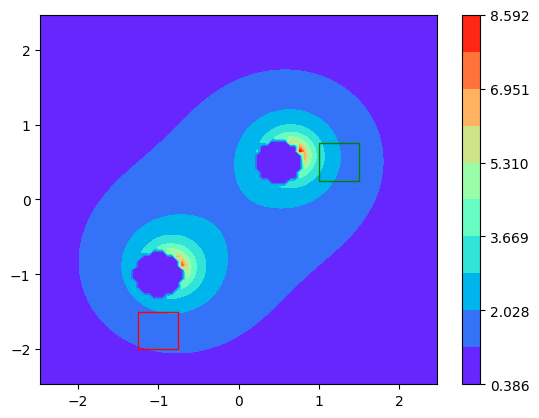

In [54]:
fig1, ax1 = plt.subplots()

contour1 = ax1.contourf(Xv, Yv, GAMMA_SOL, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar1 = fig.colorbar(contour1)

for r in APP1_ROD_POS:
    ax.scatter(r[0], r[1], color='yellow', marker='x')

for r in APP2_ROD_POS:
    ax.scatter(r[0], r[1], color='orange', marker='x')

# ROI is green
roi_box = patches.Rectangle((x_roi[0], y_roi[0]), x_roi[1] - x_roi[0], y_roi[1] - y_roi[0], fill=False, edgecolor="green")
ax1.add_patch(roi_box)

# OAR is red
oar_box = patches.Rectangle((x_oar[0], y_oar[0]), x_oar[1] - x_oar[0], y_oar[1] - y_oar[0], fill=False, edgecolor="red")
ax1.add_patch(oar_box)

In this case, our optimization has two rods open because our upper bound on the OAR is relatively large (40% of the maximum dose). If we change the upper bound on the OAR to be more constrainted (say, 20% of the maximum dose), our model closes the rod on the applicator closest to the OAR to reduce the dose.